# PayWatch: UPI behaviour features

IEEE-CIS has no UPI ids. `src/features/upi_fingerprint.py` rebuilds a user proxy (`uid`) and computes causal behaviour features from that user's earlier transactions only. This notebook inspects them and measures what they add. Aggregates only.

In [1]:
import glob, json, os, re, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 140)
T0 = time.time()
DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
find = lambda p: sorted(glob.glob(p, recursive=True))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/upi_fingerprint.py")[0]))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/evasion.py")[0]))
import engineer
from entity_history import BASE_KEYS
RAW = os.path.dirname(find("/kaggle/input/**/train_transaction.csv")[0])
import lightgbm as lgb
MODEL_DIR = os.path.dirname(find("/kaggle/input/**/lgbm_seed42.txt")[0])      # production LightGBM model directory (models/compact)
SPEC = json.load(open(f"{MODEL_DIR}/serving_spec.json"))
COLS = SPEC["features"]
SHIPPED = sorted(glob.glob(f"{MODEL_DIR}/lgbm_seed*.txt"))
ISO = json.load(open(f"{MODEL_DIR}/isotonic.json"))
raw = engineer.load_raw(RAW)
base = engineer.build_base(raw.copy(), lags=(7,), decay_lags=(), velocity=False, key_names=BASE_KEYS)
(tr, va, te), art = engineer.finalize(base, d_mode="anchor", return_artifacts=True)
(X_tr, y_tr, t_tr), (X_va, y_va, t_va), (X_te, y_te, t_te) = tr, va, te
UPI_B = {"amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
         "days_since_last_large_txn", "is_new_merchant", "is_p2p"}


def family(f):
    if f.startswith("h7_"):
        return "entity fraud history"
    if f.startswith("uid_") or f in UPI_B:
        return "UPI behaviour"
    if f.endswith("_freq"):
        return "frequency encoding"
    if re.fullmatch(r"D\d+", f):
        return "time deltas (D)"
    if re.fullmatch(r"V\d+", f):
        return "Vesta V"
    if f.startswith("id_") or f.startswith("Device"):
        return "identity / device"
    if re.fullmatch(r"[CM]\d+", f):
        return "counts / match flags (C, M)"
    return "raw transaction"


def recall_at_fpr(y, p, f):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(f, fpr, tpr))


def op_threshold(score, y, target, n_min=100):
    order = np.argsort(-score)
    tp = np.cumsum(y[order])
    n = np.arange(1, len(y) + 1)
    ok = np.where((tp / n >= target) & (n >= n_min))[0]
    return float(score[order][ok.max()]) if len(ok) else None


def shipped_boosters():
    return [lgb.Booster(model_file=p) for p in SHIPPED]


def ensemble_score(boosters, X):
    X = np.asarray(X, dtype=np.float32)
    return np.mean([b.predict(X) for b in boosters], axis=0)


print(f"device: {DEVICE} | pipeline built in {(time.time() - T0) / 60:.1f} min | train {X_tr.shape}, val {X_va.shape}, test {X_te.shape} | compact features: {len(COLS)}")

device: cpu | pipeline built in 1.1 min | train (413378, 452), val (88581, 452), test (88581, 452) | compact features: 120


In [2]:
XGB_PARAMS = dict(max_depth=10, learning_rate=0.0558, subsample=0.935, colsample_bytree=0.678, min_child_weight=1,
                  reg_lambda=1.518, gamma=0.0336, scale_pos_weight=39.3)
TAU_DAYS = 120

## 1. The user proxy

In [3]:
from upi_fingerprint import make_card_key, make_uid
n_card = len(set(make_card_key(base)))
n_uid = len(set(make_uid(base)))
print(f"transactions: {len(base):,} | distinct card composites: {n_card:,} | distinct uid proxies: {n_uid:,}")
print(f"first-ever transaction of its uid proxy (no behaviour history yet): train {(X_tr.uid_prior_tx_count == 0).mean():.1%}, test {(X_te.uid_prior_tx_count == 0).mean():.1%}")
print("caveat: uid is a reconstruction, so some real users are split across several uids and some uids merge users")

transactions: 590,540 | distinct card composites: 14,845 | distinct uid proxies: 222,382
first-ever transaction of its uid proxy (no behaviour history yet): train 40.7%, test 30.4%
caveat: uid is a reconstruction, so some real users are split across several uids and some uids merge users


## 2. The behaviour features

,feature,val_auc,direction,median_legit,median_fraud
0,amount_vs_7day_avg_ratio,0.521,higher = riskier,1.0,1.0
1,merchant_category_entropy,0.533,higher = riskier,0.0,0.0
2,hour_deviation_from_user_mean,0.504,higher = riskier,2.0,2.0
3,days_since_last_large_txn,0.505,higher = riskier,-1.0,-1.0
4,is_new_merchant,0.489,lower = riskier,0.0,0.0
5,is_p2p,0.642,higher = riskier,0.0,0.0
6,uid_amt_zscore,0.513,higher = riskier,0.0,0.0
7,uid_prior_tx_count,0.524,higher = riskier,2.0,2.0
8,uid_secs_since_prev_tx,0.420,lower = riskier,21727.0,1676.0


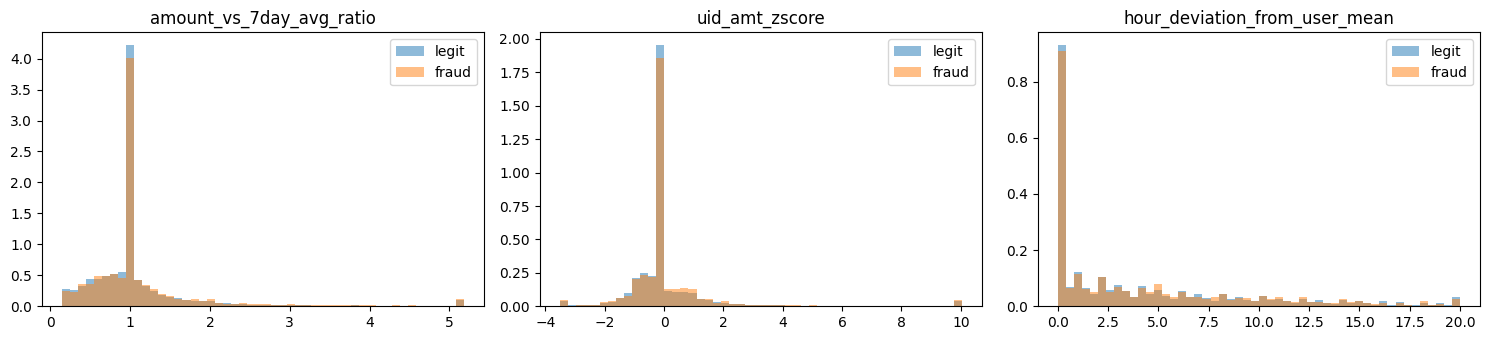

In [4]:
UPI = [c for c in ["amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
                   "days_since_last_large_txn", "is_new_merchant", "is_p2p", "uid_amt_zscore", "uid_prior_tx_count", "uid_secs_since_prev_tx"] if c in X_va]
rows = []
for c in UPI:
    v = X_va[c].to_numpy()
    a = roc_auc_score(y_va, v) if np.nanstd(v) > 0 else np.nan
    rows.append({"feature": c, "val_auc": round(a, 3), "direction": "higher = riskier" if a >= 0.5 else "lower = riskier",
                 "median_legit": round(float(np.median(v[y_va == 0])), 3), "median_fraud": round(float(np.median(v[y_va == 1])), 3)})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, ["amount_vs_7day_avg_ratio", "uid_amt_zscore", "hour_deviation_from_user_mean"]):
    v = X_va[c].to_numpy()
    lo, hi = np.percentile(v, [1, 99])
    for lab, name in ((0, "legit"), (1, "fraud")):
        a.hist(np.clip(v[y_va == lab], lo, hi), bins=50, alpha=0.5, density=True, label=name)
    a.set_title(c); a.legend()
plt.tight_layout(); plt.show()

## 3. First-time versus known users

Behaviour features need history. For a user's first transaction they carry no information, which is the hardest case for the whole system.

In [5]:
first = (X_te.uid_prior_tx_count == 0).to_numpy()
t = pd.DataFrame({"share_of_test_rows": [first.mean(), 1 - first.mean()], "fraud_rate": [y_te[first].mean(), y_te[~first].mean()],
                  "share_of_all_fraud": [y_te[first].sum() / y_te.sum(), y_te[~first].sum() / y_te.sum()]}, index=["first-time uid", "known uid"])
display(t.round(4))

,share_of_test_rows,fraud_rate,share_of_all_fraud
first-time uid,0.3043,0.0326,0.2851
known uid,0.6957,0.0358,0.7149


## 4. What do they add? A small ablation

One seed each, validation early stopping, test PR-AUC. This is indicative, not the production comparison (see `results/pipeline.json` for the 5-seed study).

,features,best_iter,test_pr_auc,test_roc_auc,recall@1%FPR
compact (all),120.0,116.0,0.6580,0.9406,0.590
without UPI behaviour,110.0,85.0,0.6548,0.9440,0.592
without entity history,105.0,595.0,0.5183,0.8760,0.456
without both,95.0,598.0,0.5168,0.8695,0.447


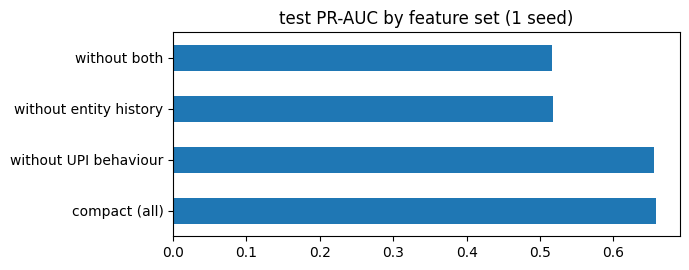

In [6]:
def fit_eval(cols, seed=42):
    w = np.exp(-(t_tr.max() - t_tr) / (TAU_DAYS * 86400.0))
    params = dict(XGB_PARAMS) if DEVICE == "cuda" else {**XGB_PARAMS, "max_depth": 8, "learning_rate": 0.1}
    m = xgb.XGBClassifier(n_estimators=3000 if DEVICE == "cuda" else 600, tree_method="hist", device=DEVICE, eval_metric="aucpr",
                          early_stopping_rounds=50, random_state=seed, n_jobs=-1, **params)
    m.fit(X_tr[cols], y_tr, sample_weight=w, eval_set=[(X_va[cols], y_va)], verbose=False)
    p = m.predict_proba(X_te[cols])[:, 1]
    return {"features": len(cols), "best_iter": int(m.best_iteration), "test_pr_auc": round(float(average_precision_score(y_te, p)), 4),
            "test_roc_auc": round(float(roc_auc_score(y_te, p)), 4), "recall@1%FPR": round(recall_at_fpr(y_te, p, 0.01), 3)}


no_upi = [c for c in COLS if family(c) != "UPI behaviour"]
no_hist = [c for c in COLS if family(c) != "entity fraud history"]
no_either = [c for c in COLS if family(c) not in ("UPI behaviour", "entity fraud history")]
res = {"compact (all)": fit_eval(COLS), "without UPI behaviour": fit_eval(no_upi), "without entity history": fit_eval(no_hist),
       "without both": fit_eval(no_either)}
abl = pd.DataFrame(res).T
display(abl)
abl.test_pr_auc.plot(kind="barh", figsize=(7, 2.8), title="test PR-AUC by feature set (1 seed)"); plt.tight_layout(); plt.show()

In [7]:
full = abl.test_pr_auc["compact (all)"]
print(f"removing UPI behaviour features: PR-AUC {abl.test_pr_auc['without UPI behaviour'] - full:+.4f}")
print(f"removing entity fraud history:   PR-AUC {abl.test_pr_auc['without entity history'] - full:+.4f}")
print(f"removing both:                   PR-AUC {abl.test_pr_auc['without both'] - full:+.4f}")
print("single seed, so differences of a few thousandths are noise; the size of each effect is what matters")

removing UPI behaviour features: PR-AUC -0.0032
removing entity fraud history:   PR-AUC -0.1397
removing both:                   PR-AUC -0.1412
single seed, so differences of a few thousandths are noise; the size of each effect is what matters


## Reading the results

The behaviour features are causal and reconstructed from a proxy id, and the ablation above measures what they add instead of assuming it. First-time users, where none of them can help, are a large share of test fraud, which is why recall on new identities is the known weak spot.